# 2 · Measuring applause

Each keynote's audio is decoded to 32 kHz mono and passed through PANNs
`Cnn14_DecisionLevelMax`, a CNN trained on AudioSet's 527 sound classes. The model emits a
probability per class every 0.32 s; we keep 13 classes (speech, applause, clapping,
cheering, laughter, music, ...) averaged to one row per second. An ovation is a stretch where
the clap score `max(P(applause), P(clapping))` crosses an onset threshold, with hysteresis.

The thresholds are tuned **only** on human-written caption tags (`[Applause]`,
`[Cheering and applause]`, ...) that professional captioners added to official uploads.
Half of the caption-labelled videos tune the thresholds, the other half measure accuracy.

In [1]:
%load_ext autoreload
%autoreload 2
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display
from unpacked_applause.config import FIGURES, PROCESSED, TABLES
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
validation = json.loads((TABLES / "detector_validation.json").read_text())
{k: v for k, v in validation.items() if not k.endswith("_ids")}

{'test_precision': 0.758789860997547,
 'test_recall': 0.919921875,
 'test_f1': 0.8316226981579556,
 'test_auc_pooled': 0.9102512594513352,
 'test_ap_pooled': 0.5056155495336001,
 'params': {'on': 0.05, 'off': 0.02, 'min_dur': 2, 'merge_gap': 1}}

In [3]:
grid = pd.read_csv(TABLES / "detector_grid.csv")
grid.head(10)

,on,off,min_dur,precision,recall,f1
0,0.0500,0.0200,2,0.8225,0.9177,0.8675
1,0.0500,0.0200,1,0.8187,0.9205,0.8666
2,0.0500,0.0300,2,0.8218,0.9148,0.8658
3,0.0750,0.0300,1,0.8259,0.9098,0.8658
4,0.0500,0.0200,3,0.8372,0.8962,0.8657
5,0.0750,0.0300,2,0.8275,0.9069,0.8654
6,0.0500,0.0300,1,0.8160,0.9198,0.8648
7,0.0750,0.0450,1,0.8242,0.9091,0.8646
8,0.1000,0.0400,1,0.8286,0.9026,0.8640
9,0.0750,0.0450,2,0.8296,0.9012,0.8639


In [4]:
per_event = pd.read_csv(TABLES / "detector_per_event.csv")
per_event.describe()[["auc", "ap", "label_share"]]

,auc,ap,label_share
count,39.0000,39.0000,39.0000
mean,0.8809,0.5597,0.0562
std,0.1203,0.2577,0.0343
min,0.4831,0.0378,0.0101
25%,0.8515,0.3373,0.0248
50%,0.9276,0.5769,0.0491
75%,0.9682,0.8062,0.0831
max,0.9861,0.9349,0.1231


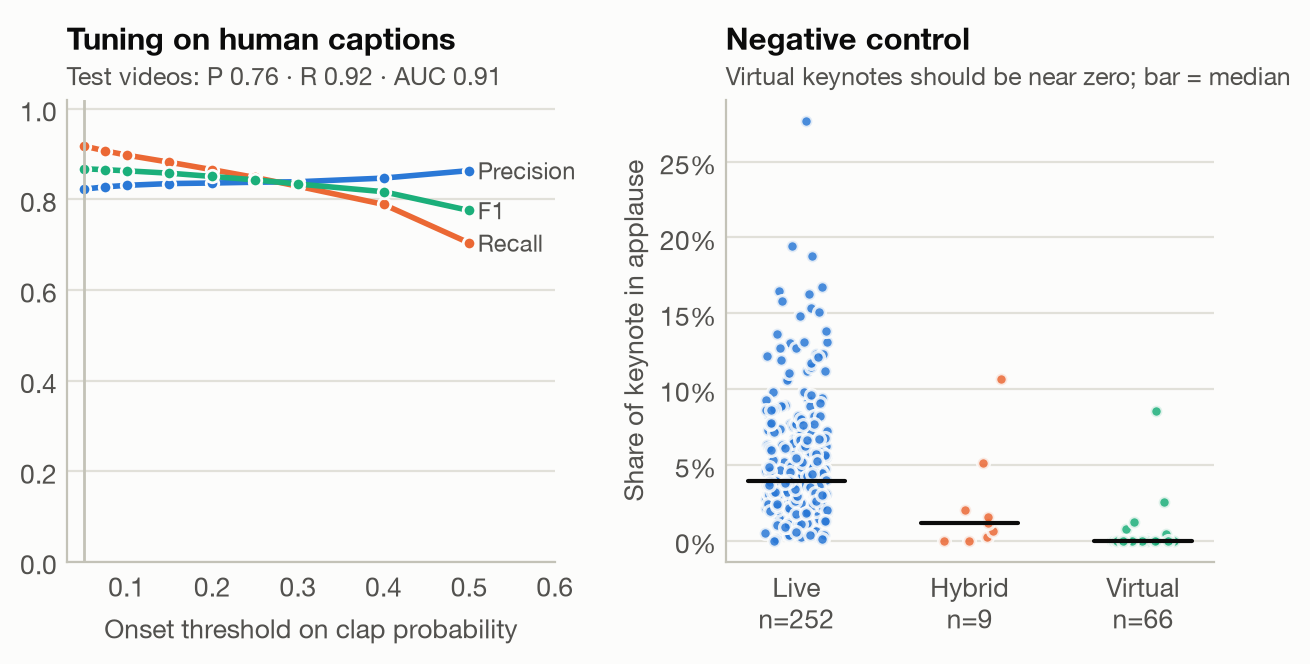

In [5]:
display(Image(filename=str(FIGURES / "detector_validation.png")))

## An example timeline

Detected ovations (shaded) against the human caption tags (ticks under the axis).

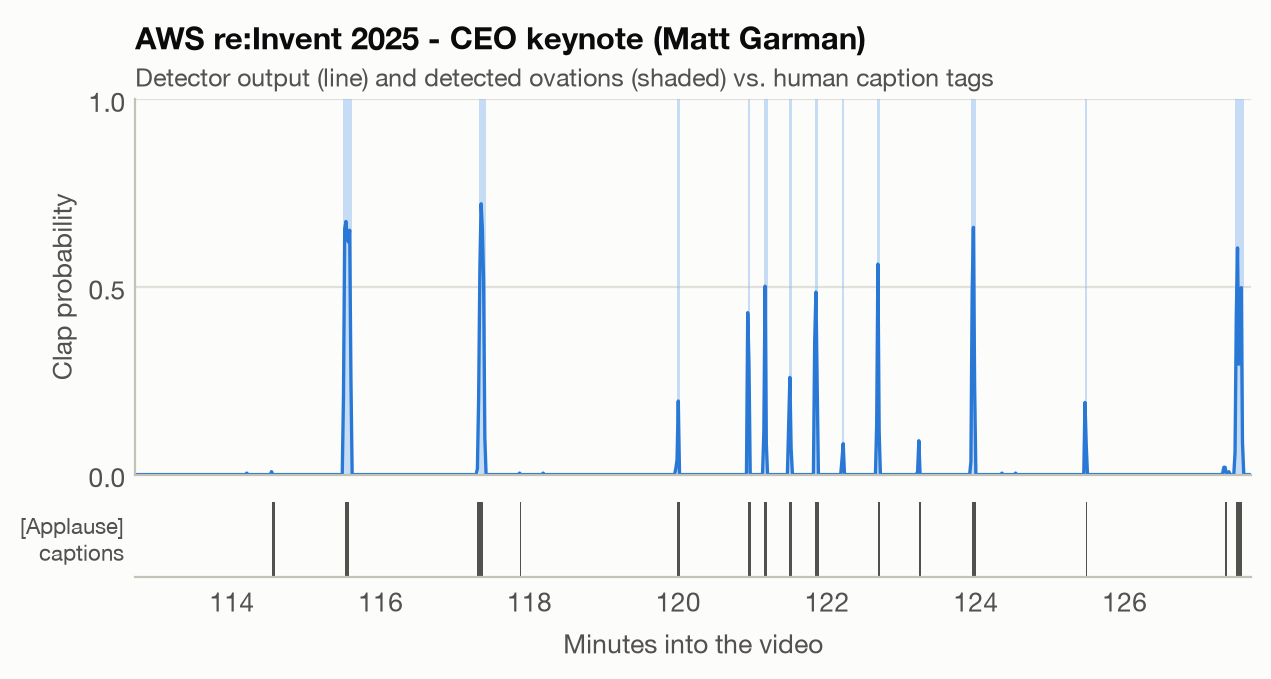

In [6]:
for p in sorted(FIGURES.glob("timeline_*.png")):
    display(Image(filename=str(p)))

## Event-level applause measures

In [7]:
features = pd.read_parquet(PROCESSED / "applause_features.parquet")
from unpacked_applause.catalog import load_events
f = load_events()[["event_id", "company", "audience"]].merge(features, on="event_id")
f.groupby("audience")[["applause_share", "applause_per_min", "applause_max_s", "cheer_share"]].median()

,applause_share,applause_per_min,applause_max_s,cheer_share
audience,,,,
hybrid,0.0118,0.1654,7.0000,0.0000
live,0.0393,0.4025,11.0000,0.0004
virtual,0.0000,0.0000,0.0000,0.0000


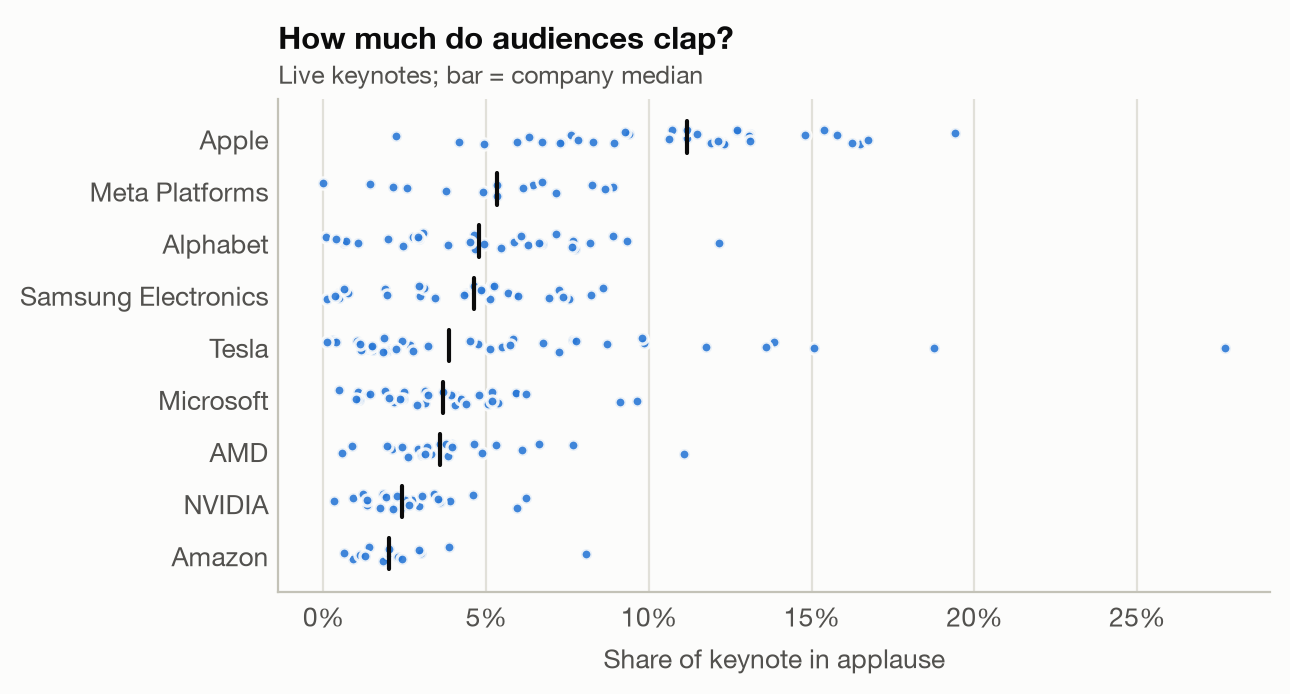

In [8]:
display(Image(filename=str(FIGURES / "applause_by_company.png")))